# Lab CNN : Classification des images de fruits
## But:

Être capable de concevoir et réaliser une IA permettant la classification des images de fruits.

**Keywords :  Fruits dataset, PyTorch, CNN**

<center>Copyright : Dr Mohammed BOUSMAH EMSI-2026 — bousmah@gmail.com</center>


uv add torch torchvision numpy matplotlib

In [3]:
# Télécharger le jeu de données original
!wget -O fruits.zip https://bitbucket.org/ishaanjav/code-and-deploy-custom-tensorflow-lite-model/raw/a4febbfee178324b2083e322cdead7465d6fdf95/fruits.zip

# Extraire les images dans fruits/train, fruits/validation et fruits/test
!unzip -o fruits.zip

--2026-10-09 06:08:23--  https://bitbucket.org/ishaanjav/code-and-deploy-custom-tensorflow-lite-model/raw/a4febbfee178324b2083e322cdead7465d6fdf95/fruits.zip
Resolving bitbucket.org (bitbucket.org)... 185.166.142.22, 185.166.142.23, 185.166.142.21
Connecting to bitbucket.org (bitbucket.org)|185.166.142.22|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 105946856 (101M) [application/zip]
Saving to: ‘fruits.zip’

fruits.zip          100%[===================>] 101.04M  16.8MB/s    in 6.6s    

2026-10-09 06:08:32 (15.4 MB/s) - ‘fruits.zip’ saved [105946856/105946856]

Archive:  fruits.zip
   creating: fruits
  inflating: __MACOSX/._fruits       
  inflating: fruits/.DS_Store        
  inflating: __MACOSX/fruits/._.DS_Store  
   creating: fruits/test
   creating: fruits/train
   creating: fruits/validation
   creating: fruits/test/apple
  inflating: fruits/test/.DS_Store   
  inflating: __MACOSX/fruits/test/._.DS_Store  
   creating: fruits/test/banana
   creating

In [4]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import numpy as np

# GPU Apple Silicon (MPS), NVIDIA (CUDA) ou CPU
device = torch.device("mps" if torch.backends.mps.is_available() else
                      "cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: mps


In [5]:
img_height, img_width = 64, 64
batch_size = 20

# ImageFolder : dossiers de classes, identiques aux données originales.
# ToTensor convertit les pixels en [0, 1] et transpose HWC -> CHW.
transform = transforms.Compose([
    transforms.Resize((img_height, img_width)),
    transforms.ToTensor(),
])

train_data = datasets.ImageFolder("fruits/train", transform=transform)
val_data = datasets.ImageFolder("fruits/validation", transform=transform)
test_data = datasets.ImageFolder("fruits/test", transform=transform)

# Vérifier que les labels correspondent dans les 3 partitions.
assert train_data.classes == val_data.classes == test_data.classes, "Classes incohérentes"
train_ds = DataLoader(train_data, batch_size=batch_size, shuffle=True)
val_ds = DataLoader(val_data, batch_size=batch_size, shuffle=False)
test_ds = DataLoader(test_data, batch_size=batch_size, shuffle=False)
print('Classes:', train_data.classes)

Classes: ['apple', 'banana', 'orange']


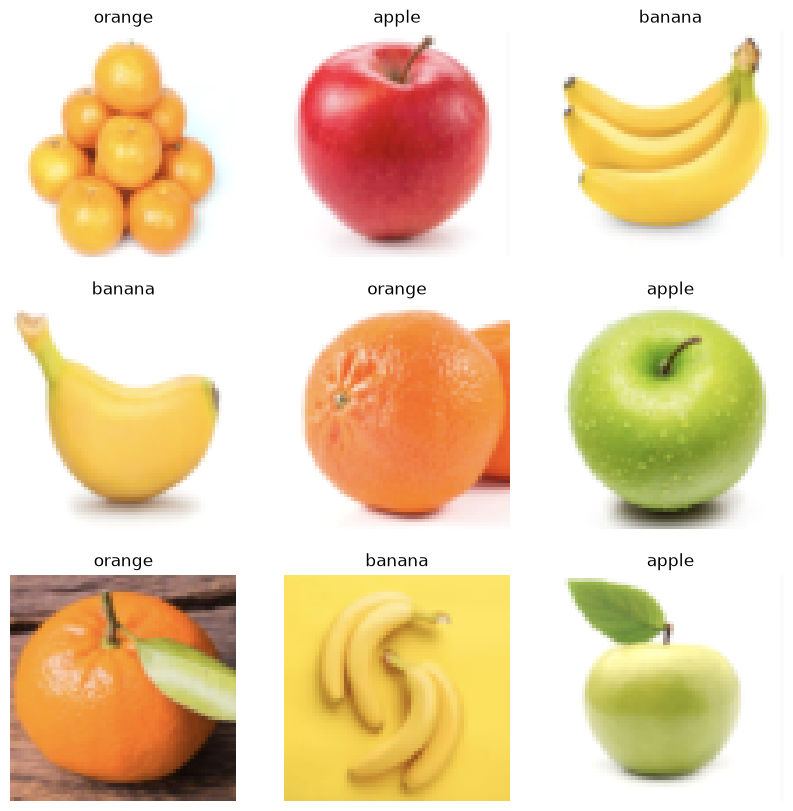

In [6]:
class_names = train_data.classes  # ordre défini par ImageFolder
plt.figure(figsize=(10, 10))
images, labels = next(iter(train_ds))
for i in range(min(9, len(images))):
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow(images[i].permute(1, 2, 0).numpy())
    plt.title(class_names[labels[i].item()])
    plt.axis("off")
plt.show()

In [7]:
# Même architecture que le CNN Keras original.
# Conv2d PyTorch reçoit les images au format (N, C, H, W).
model = nn.Sequential(
    nn.Conv2d(3, 32, kernel_size=3), nn.ReLU(),
    nn.MaxPool2d(kernel_size=2),
    nn.Conv2d(32, 32, kernel_size=3), nn.ReLU(),
    nn.MaxPool2d(kernel_size=2),
    nn.Conv2d(32, 32, kernel_size=3), nn.ReLU(),
    nn.MaxPool2d(kernel_size=2),
    nn.Flatten(),
    nn.Linear(32 * 6 * 6, 128), nn.ReLU(),
    nn.Linear(128, len(class_names))
).to(device)

In [8]:
# Equivalents de model.compile : optimizer, loss et métrique accuracy.
optimizer = torch.optim.Adam(model.parameters())
criterion = nn.CrossEntropyLoss()  # attend les logits (sans softmax)

def run_epoch(loader, training=False):
    model.train() if training else model.eval()
    loss_sum, correct, total = 0.0, 0, 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        with torch.set_grad_enabled(training):
            logits = model(images)
            loss = criterion(logits, labels)
            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
        loss_sum += loss.item() * labels.size(0)
        correct += (logits.argmax(dim=1) == labels).sum().item()
        total += labels.size(0)
    return loss_sum / total, correct / total

In [16]:
# Equivalent de model.fit(..., epochs=10)
epochs = 15
history = {"train_loss": [], "train_accuracy": [], "val_loss": [], "val_accuracy": []}
for epoch in range(epochs):
    train_loss, train_acc = run_epoch(train_ds, training=True)
    val_loss, val_acc = run_epoch(val_ds, training=False)
    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_acc)
    print(f"Epoch {epoch+1}/{epochs} - loss: {train_loss:.4f} - accuracy: {train_acc:.4f} - "
          f"val_loss: {val_loss:.4f} - val_accuracy: {val_acc:.4f}")

Epoch 1/15 - loss: 0.0916 - accuracy: 0.9739 - val_loss: 0.3126 - val_accuracy: 0.9242
Epoch 2/15 - loss: 0.0661 - accuracy: 0.9826 - val_loss: 0.1965 - val_accuracy: 0.9394
Epoch 3/15 - loss: 0.0524 - accuracy: 0.9870 - val_loss: 0.2849 - val_accuracy: 0.9394
Epoch 4/15 - loss: 0.0629 - accuracy: 0.9783 - val_loss: 0.2185 - val_accuracy: 0.9394
Epoch 5/15 - loss: 0.0666 - accuracy: 0.9783 - val_loss: 0.3094 - val_accuracy: 0.9091
Epoch 6/15 - loss: 0.0683 - accuracy: 0.9783 - val_loss: 0.0791 - val_accuracy: 0.9848
Epoch 7/15 - loss: 0.1306 - accuracy: 0.9543 - val_loss: 0.2366 - val_accuracy: 0.9394
Epoch 8/15 - loss: 0.0514 - accuracy: 0.9870 - val_loss: 0.2102 - val_accuracy: 0.9545
Epoch 9/15 - loss: 0.0274 - accuracy: 0.9957 - val_loss: 0.1732 - val_accuracy: 0.9545
Epoch 10/15 - loss: 0.0255 - accuracy: 0.9935 - val_loss: 0.2491 - val_accuracy: 0.9545
Epoch 11/15 - loss: 0.0308 - accuracy: 0.9935 - val_loss: 0.1603 - val_accuracy: 0.9545
Epoch 12/15 - loss: 0.0384 - accuracy: 0.

In [17]:
# Equivalent de model.evaluate(test_ds)
test_loss, test_accuracy = run_epoch(test_ds, training=False)
print(f"Test loss: {test_loss:.4f} | Test accuracy: {test_accuracy:.4f}")

Test loss: 0.1860 | Test accuracy: 0.9538


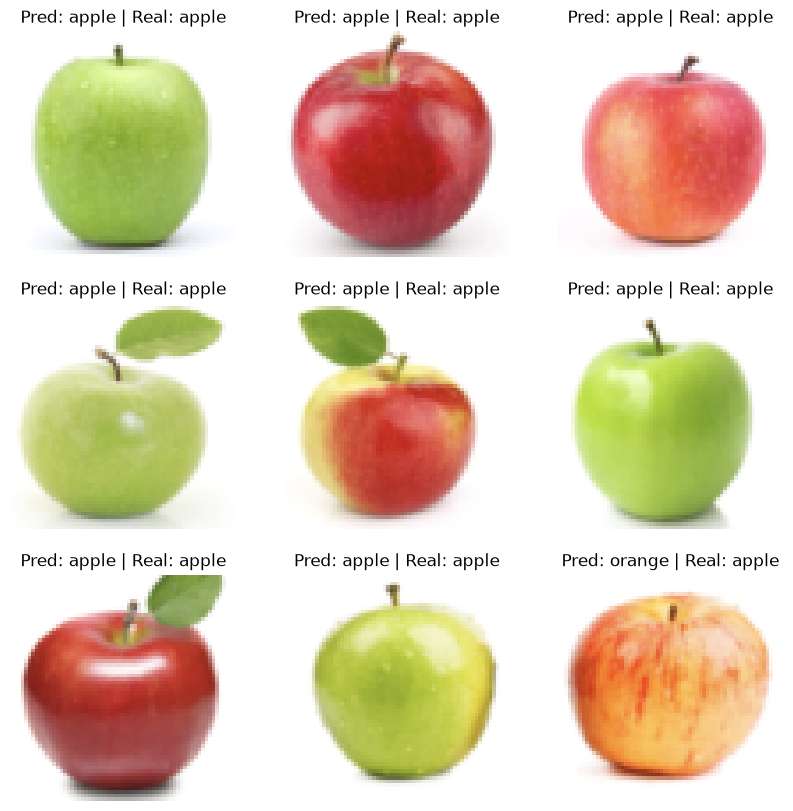

In [20]:
plt.figure(figsize=(10, 10))
images, labels = next(iter(test_ds))
model.eval()
with torch.no_grad():
    classifications = model(images.to(device)).cpu()
for i in range(min(9, len(images))):
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow(images[i].permute(1, 2, 0).numpy())
    index = classifications[i].argmax().item()
    plt.title("Pred: " + class_names[index] + " | Real: " + class_names[labels[i].item()])
    plt.axis("off")
plt.show()

In [13]:
# PyTorch : sauvegarde native (.pth) en remplacement de TFLite.
# TFLiteConverter est propre à TensorFlow et n'a pas d'équivalent direct en PyTorch.
torch.save({
    "model_state_dict": model.state_dict(),
    "classes": class_names,
    "image_size": (img_height, img_width),
}, "model_fruits.pth")
print("Modèle enregistré : model_fruits.pth")

# Pour le déploiement multi-frameworks : export ONNX possible séparément
# (nécessite le package 'onnx' et, selon la version de torch, 'onnxscript').

Modèle enregistré : model_fruits.pth


In [15]:
# Equivalent pédagogique de model.summary() : structure et nombre de paramètres.
print(model)
print("Nombre total de paramètres :", sum(p.numel() for p in model.parameters()))
print("Paramètres entraînables :", sum(p.numel() for p in model.parameters() if p.requires_grad))
print("PyTorch Fruit Classifier")

Sequential(
  (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1))
  (1): ReLU()
  (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1))
  (4): ReLU()
  (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (6): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1))
  (7): ReLU()
  (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (9): Flatten(start_dim=1, end_dim=-1)
  (10): Linear(in_features=1152, out_features=128, bias=True)
  (11): ReLU()
  (12): Linear(in_features=128, out_features=3, bias=True)
)
Nombre total de paramètres : 167363
Paramètres entraînables : 167363
PyTorch Fruit Classifier



=== Visualisation des filtres CNN ===

Couche : 0 | Shape des filtres : (32, 3, 3, 3)


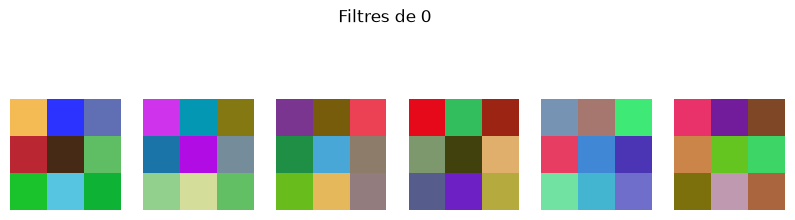


Couche : 3 | Shape des filtres : (32, 32, 3, 3)


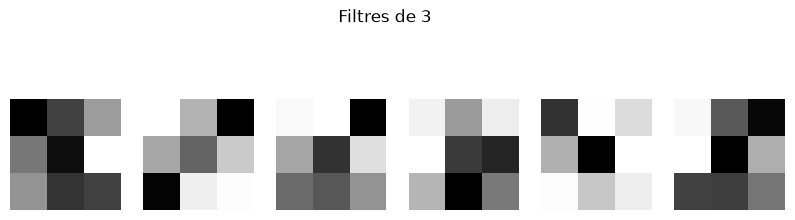


Couche : 6 | Shape des filtres : (32, 32, 3, 3)


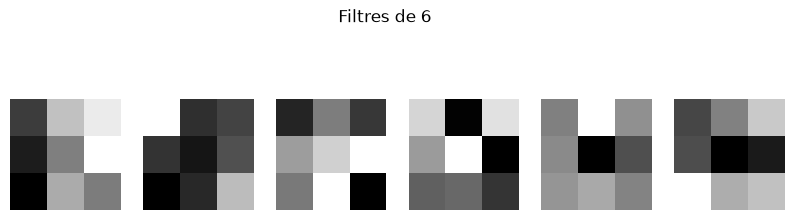

In [14]:
# -------------------------------------------------------------
# 🧠 Step 5 : Visualiser les filtres de chaque couche Conv2d
# -------------------------------------------------------------
print("\n=== Visualisation des filtres CNN ===")
for name, layer in model.named_modules():
    if isinstance(layer, nn.Conv2d):
        # PyTorch : (out_channels, in_channels, kH, kW)
        filters = layer.weight.detach().cpu().numpy()
        print(f"\nCouche : {name} | Shape des filtres : {filters.shape}")
        f_min, f_max = filters.min(), filters.max()
        filters = (filters - f_min) / (f_max - f_min + 1e-8)
        n_filters = min(filters.shape[0], 6)
        plt.figure(figsize=(10, 3))
        plt.suptitle(f"Filtres de {name}")
        for i in range(n_filters):
            f = filters[i]  # (in_channels, kH, kW)
            plt.subplot(1, n_filters, i + 1)
            if f.shape[0] == 3:
                plt.imshow(np.transpose(f, (1, 2, 0)))
            else:
                plt.imshow(f[0], cmap="gray")
            plt.axis("off")
        plt.show()